# 07 — Explainability & Risk Segmentation

This notebook explains the selected CatBoost fraud model and translates calibrated fraud probabilities into interpretable risk segments.

The objectives are to:
- identify the most influential fraud-risk features,
- examine SHAP-based global feature importance,
- explain individual application predictions,
- create practical Low / Medium / High risk bands,
- connect model explanations with the review strategy developed previously.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path(
    r"D:\bank-account-fraud-decision-system"
)

data_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "fraud_modeling_dataset.parquet"
)

df = pd.read_parquet(data_path)

train_df = df[
    df["month"].between(0, 4)
].copy()

calibration_df = df[
    df["month"] == 5
].copy()

strategy_df = df[
    df["month"] == 6
].copy()

test_df = df[
    df["month"] == 7
].copy()

target = "fraud_bool"

X_train = train_df.drop(columns=[target])
y_train = train_df[target]

X_test = test_df.drop(columns=[target])
y_test = test_df[target]

In [2]:
from catboost import CatBoostClassifier

cat_features = [
    "payment_type",
    "employment_status",
    "housing_status",
    "source",
    "device_os"
]

X_train_cb = X_train.copy()
X_test_cb = X_test.copy()

for col in cat_features:
    X_train_cb[col] = (
        X_train_cb[col]
        .fillna("Missing")
        .astype(str)
    )

    X_test_cb[col] = (
        X_test_cb[col]
        .fillna("Missing")
        .astype(str)
    )

final_cat_model = CatBoostClassifier(
    depth=5,
    learning_rate=0.05,
    iterations=631,
    loss_function="Logloss",
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=False
)

final_cat_model.fit(
    X_train_cb,
    y_train,
    cat_features=cat_features
)

CatBoostClassifier(auto_class_weights='Balanced', depth=5, iterations=631, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=False)

## 1. Native CatBoost Feature Importance

CatBoost's built-in feature importance provides a first global view of which variables contribute most strongly to the model's predictions.

In [3]:
feature_importance = pd.DataFrame({
    "feature": X_train_cb.columns,
    "importance": final_cat_model.get_feature_importance()
})

feature_importance = (
    feature_importance
    .sort_values(
        "importance",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    feature_importance.head(20)
)

,feature,importance
0,current_address_months_count,6.934130
1,device_os,6.443015
2,has_other_cards,6.320211
3,credit_risk_score,5.430752
4,customer_age,4.917216
5,housing_status,4.726620
6,intended_balcon_amount,4.529904
7,name_email_similarity,4.445584
8,prev_address_months_count,4.410936
9,bank_branch_count_8w,4.227908


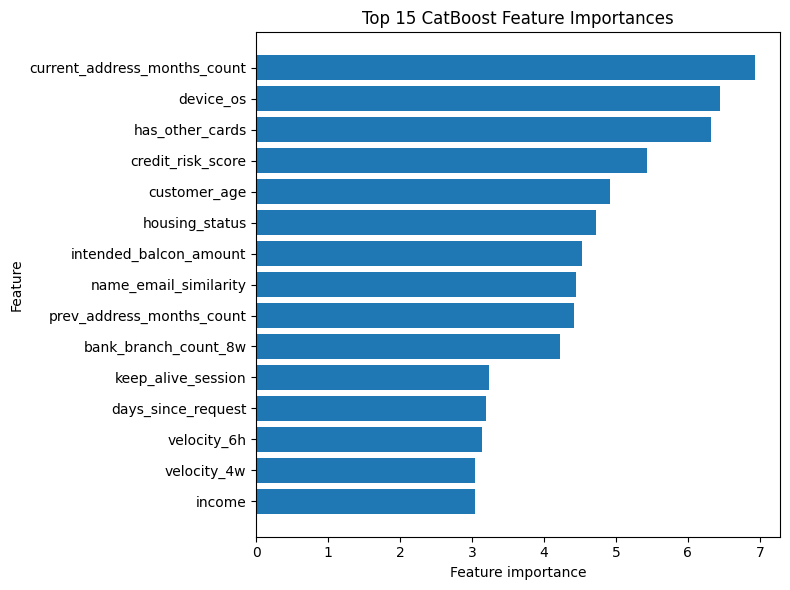

In [4]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15)

plt.figure(figsize=(8, 6))

plt.barh(
    top_features["feature"][::-1],
    top_features["importance"][::-1]
)

plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.title("Top 15 CatBoost Feature Importances")
plt.tight_layout()
plt.show()

## 2. SHAP-Based Global Explainability

SHAP values are used to explain how individual features influence CatBoost fraud-risk predictions.

Positive SHAP values push a prediction toward higher fraud risk, while negative SHAP values push it toward lower fraud risk.

Because the test dataset is large, SHAP analysis is performed on a reproducible sample for computational efficiency.

In [5]:
from catboost import Pool
import shap

In [6]:
shap_sample = X_test_cb.sample(
    n=5000,
    random_state=42
)

shap_pool = Pool(
    shap_sample,
    cat_features=cat_features
)

In [7]:
shap_values_full = final_cat_model.get_feature_importance(
    shap_pool,
    type="ShapValues"
)

print(shap_values_full.shape)

(5000, 41)


In [8]:
shap_values = shap_values_full[:, :-1]

base_values = shap_values_full[:, -1]

print("SHAP values shape:", shap_values.shape)
print("Number of features:", shap_sample.shape[1])

SHAP values shape: (5000, 40)
Number of features: 40


In [9]:
shap_importance = pd.DataFrame({
    "feature": shap_sample.columns,
    "mean_abs_shap": np.abs(
        shap_values
    ).mean(axis=0)
})

shap_importance = (
    shap_importance
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    shap_importance.head(20)
)

,feature,mean_abs_shap
0,device_os,0.501186
1,has_other_cards,0.383512
2,keep_alive_session,0.344667
3,current_address_months_count,0.335697
4,email_is_free,0.291159
5,housing_status,0.287704
6,name_email_similarity,0.281367
7,phone_home_valid,0.280685
8,month,0.254722
9,income,0.231602


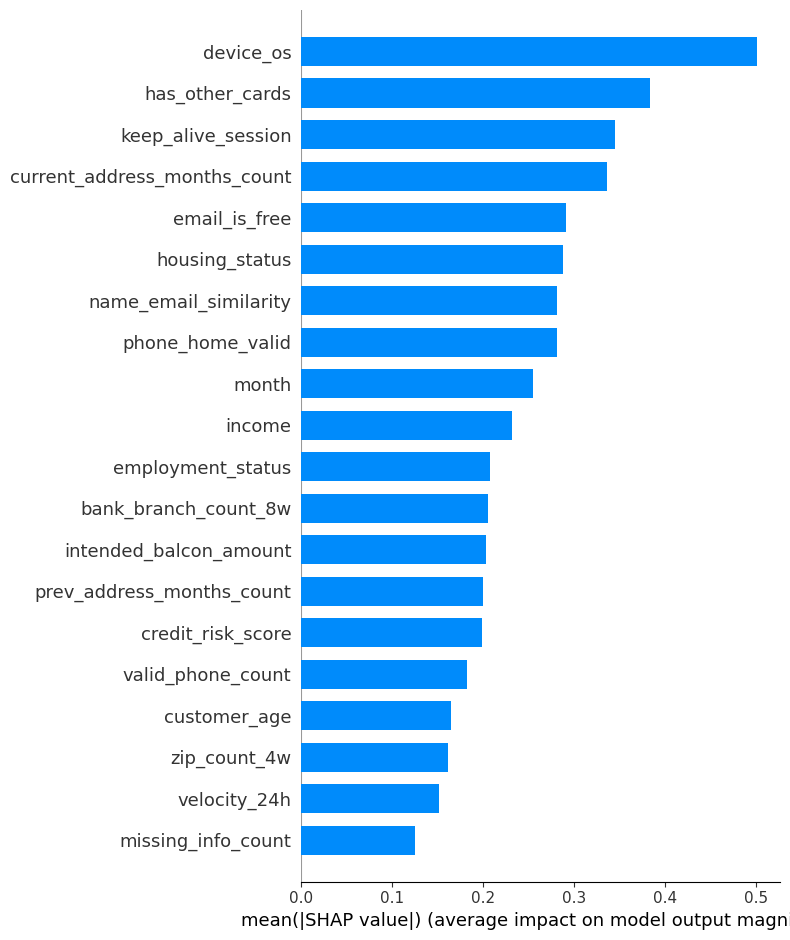

In [10]:
shap.summary_plot(
    shap_values,
    shap_sample,
    plot_type="bar",
    max_display=20
)

### SHAP Global Importance Interpretation

SHAP analysis confirms that the CatBoost model relies on a diverse set of fraud-risk signals rather than a single dominant predictor.

The strongest global drivers include device operating system, card ownership, session persistence, address-history duration, free-email usage, housing status, name-email similarity, phone validity, temporal period, and income.

These results broadly agree with the earlier exploratory analysis, where several of the same variables showed meaningful fraud-rate differences.

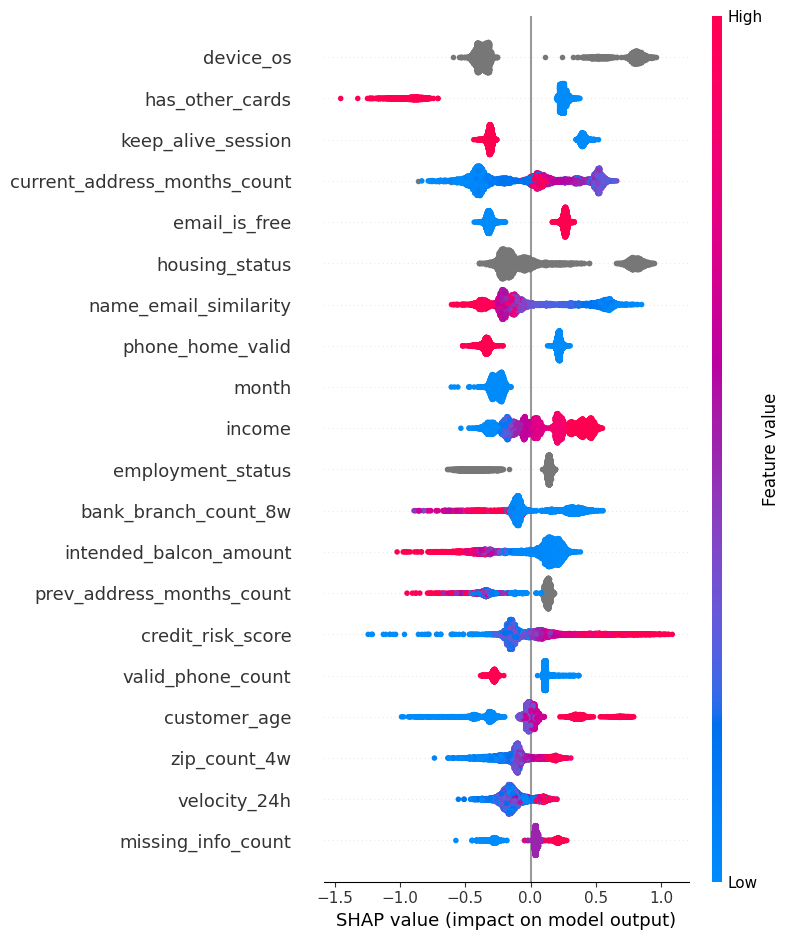

In [11]:
shap.summary_plot(
    shap_values,
    shap_sample,
    max_display=20
)

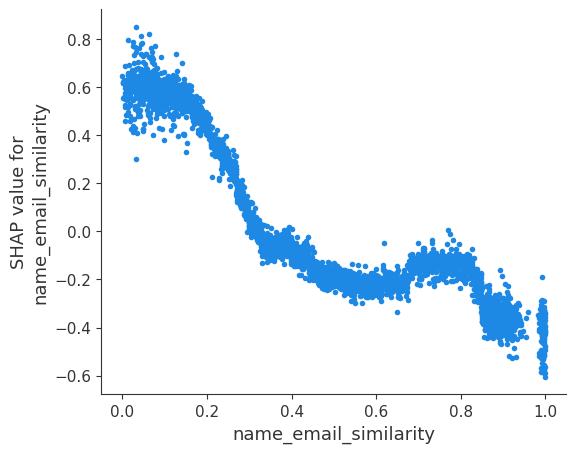

In [12]:
shap.dependence_plot(
    "name_email_similarity",
    shap_values,
    shap_sample,
    interaction_index=None
)

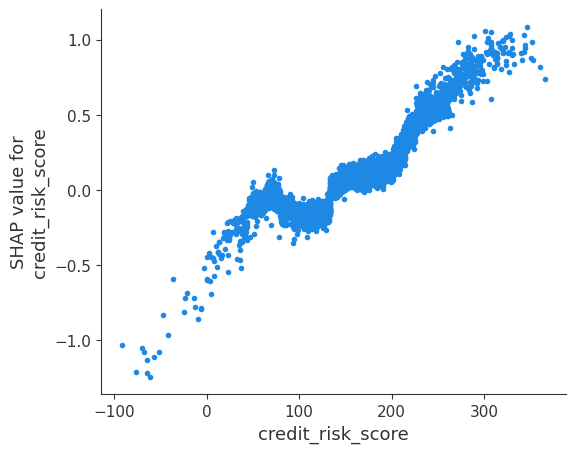

In [13]:
shap.dependence_plot(
    "credit_risk_score",
    shap_values,
    shap_sample,
    interaction_index=None
)

## 3. Risk Segmentation

Calibrated fraud probabilities are translated into operational risk bands.

Risk-band thresholds are derived only from the month-6 strategy-validation period:

- Critical: top 1% highest-risk applications
- High: next 4%
- Medium: next 15%
- Low: remaining 80%

The High and Critical bands together represent the previously selected 5% manual-review capacity.

The thresholds are then frozen and applied unchanged to the month-7 test period.

In [14]:
calibration_df = df[
    df["month"] == 5
].copy()

strategy_df = df[
    df["month"] == 6
].copy()

X_cal = calibration_df.drop(columns=[target])
y_cal = calibration_df[target]

X_strategy = strategy_df.drop(columns=[target])
y_strategy = strategy_df[target]

In [15]:
X_cal_cb = X_cal.copy()
X_strategy_cb = X_strategy.copy()

for col in cat_features:
    X_cal_cb[col] = (
        X_cal_cb[col]
        .fillna("Missing")
        .astype(str)
    )

    X_strategy_cb[col] = (
        X_strategy_cb[col]
        .fillna("Missing")
        .astype(str)
    )

In [16]:
from sklearn.linear_model import LogisticRegression

eps = 1e-6

cal_raw_proba = final_cat_model.predict_proba(
    X_cal_cb
)[:, 1]

cal_raw_clipped = np.clip(
    cal_raw_proba,
    eps,
    1 - eps
)

cal_logits = np.log(
    cal_raw_clipped /
    (1 - cal_raw_clipped)
).reshape(-1, 1)

platt_calibrator = LogisticRegression()

platt_calibrator.fit(
    cal_logits,
    y_cal
)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [17]:
strategy_raw_proba = final_cat_model.predict_proba(
    X_strategy_cb
)[:, 1]

strategy_raw_clipped = np.clip(
    strategy_raw_proba,
    eps,
    1 - eps
)

strategy_logits = np.log(
    strategy_raw_clipped /
    (1 - strategy_raw_clipped)
).reshape(-1, 1)

strategy_calibrated_proba = (
    platt_calibrator
    .predict_proba(strategy_logits)[:, 1]
)

In [18]:
critical_threshold = np.quantile(
    strategy_calibrated_proba,
    0.99
)

high_threshold = np.quantile(
    strategy_calibrated_proba,
    0.95
)

medium_threshold = np.quantile(
    strategy_calibrated_proba,
    0.80
)

print("Medium threshold:", medium_threshold)
print("High threshold:", high_threshold)
print("Critical threshold:", critical_threshold)

Medium threshold: 0.012673651616958732
High threshold: 0.05820484107195065
Critical threshold: 0.19175058691953206


In [19]:
def assign_risk_band(probability):
    if probability >= critical_threshold:
        return "Critical"
    elif probability >= high_threshold:
        return "High"
    elif probability >= medium_threshold:
        return "Medium"
    else:
        return "Low"

In [20]:
strategy_risk = pd.DataFrame({
    "fraud_bool": y_strategy.values,
    "calibrated_probability": strategy_calibrated_proba
})

strategy_risk["risk_band"] = (
    strategy_risk["calibrated_probability"]
    .apply(assign_risk_band)
)

In [21]:
risk_summary = (
    strategy_risk
    .groupby("risk_band", observed=True)
    .agg(
        applications=("fraud_bool", "count"),
        fraud_cases=("fraud_bool", "sum"),
        avg_probability=(
            "calibrated_probability",
            "mean"
        )
    )
)

risk_summary["fraud_rate_pct"] = (
    risk_summary["fraud_cases"]
    / risk_summary["applications"]
    * 100
)

risk_summary["application_share_pct"] = (
    risk_summary["applications"]
    / len(strategy_risk)
    * 100
)

risk_summary = risk_summary.reindex(
    ["Low", "Medium", "High", "Critical"]
)

display(risk_summary)

,applications,fraud_cases,avg_probability,fraud_rate_pct,application_share_pct
risk_band,,,,,
Low,86534,268,0.002989,0.309705,79.999630
Medium,16225,453,0.026360,2.791988,14.999815
High,4327,433,0.099403,10.006933,4.000259
Critical,1082,296,0.324525,27.356747,1.000296


### Risk Segmentation Interpretation

The calibrated fraud-risk segmentation produces clear separation between risk groups.

The Low-risk segment contains approximately 80% of applications and has an observed fraud rate of only 0.31%. In contrast, the High-risk segment has a fraud rate of approximately 10.01%, while the Critical-risk segment reaches 27.36%.

High and Critical applications together represent only 5% of the validation population but contain 729 of 1,450 fraud cases, corresponding to approximately 50.3% of all detected fraud.

The strong monotonic increase in observed fraud rate across Low, Medium, High, and Critical segments indicates that the calibrated model provides an operationally meaningful risk-ranking system.

In [22]:
test_raw_proba = final_cat_model.predict_proba(
    X_test_cb
)[:, 1]

In [23]:
test_raw_clipped = np.clip(
    test_raw_proba,
    eps,
    1 - eps
)

test_logits = np.log(
    test_raw_clipped /
    (1 - test_raw_clipped)
).reshape(-1, 1)

test_calibrated_proba = (
    platt_calibrator
    .predict_proba(test_logits)[:, 1]
)

In [24]:
test_risk = pd.DataFrame({
    "fraud_bool": y_test.values,
    "calibrated_probability": test_calibrated_proba
})

test_risk["risk_band"] = (
    test_risk["calibrated_probability"]
    .apply(assign_risk_band)
)

In [25]:
test_risk_summary = (
    test_risk
    .groupby("risk_band", observed=True)
    .agg(
        applications=("fraud_bool", "count"),
        fraud_cases=("fraud_bool", "sum"),
        avg_probability=(
            "calibrated_probability",
            "mean"
        )
    )
)

test_risk_summary["fraud_rate_pct"] = (
    test_risk_summary["fraud_cases"]
    / test_risk_summary["applications"]
    * 100
)

test_risk_summary["application_share_pct"] = (
    test_risk_summary["applications"]
    / len(test_risk)
    * 100
)

test_risk_summary = test_risk_summary.reindex(
    ["Low", "Medium", "High", "Critical"]
)

display(test_risk_summary)

,applications,fraud_cases,avg_probability,fraud_rate_pct,application_share_pct
risk_band,,,,,
Low,82619,345,0.002470,0.417579,85.312310
Medium,10861,414,0.025953,3.811804,11.215059
High,2697,416,0.099998,15.424546,2.784920
Critical,666,253,0.320322,37.987988,0.687711


### Out-of-Time Risk Segment Validation

The frozen risk thresholds continued to separate fraud risk effectively in the unseen month-7 test period.

The population distribution shifted relative to month 6, with 85.31% of applications classified as Low risk and only 0.69% classified as Critical risk. This indicates temporal drift in the score distribution.

Despite this shift, the ordering of observed fraud risk remained strongly monotonic. Fraud rates increased from 0.42% in the Low-risk segment to 3.81% in Medium, 15.42% in High, and 37.99% in Critical.

The High and Critical groups together represented only 3.47% of month-7 applications while containing 669 of 1,428 fraud cases, equivalent to 46.85% fraud recall. This demonstrates that the frozen risk segmentation retained strong out-of-time discrimination.

## 4. Local SHAP Explanations

Global SHAP analysis identifies the features that matter across the overall population. Local SHAP explanations are used to understand why individual applications receive high or low fraud-risk scores.

Examples are selected from the unseen month-7 test period.

In [26]:
critical_indices = test_risk[
    test_risk["risk_band"] == "Critical"
].index

example_idx = critical_indices[0]

example_application = X_test_cb.iloc[[example_idx]]

print(
    "Actual fraud label:",
    y_test.iloc[example_idx]
)

print(
    "Calibrated fraud probability:",
    test_calibrated_proba[example_idx]
)

display(example_application)

Actual fraud label: 0
Calibrated fraud probability: 0.20126693105915308


,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_6h,...,prev_address_months_count_missing,current_address_months_count_missing,bank_months_count_missing,session_length_in_minutes_missing,device_distinct_emails_8w_missing,missing_info_count,valid_phone_count,address_history_complete,low_identity_consistency,high_credit_request
903296,0.8,0.208923,NaN,358.0,30,0.008837,-0.925464,AB,1870,1268.556171,...,1,0,0,0,0,1,1,0,1,1


In [27]:
example_pool = Pool(
    example_application,
    cat_features=cat_features
)

example_shap_full = (
    final_cat_model
    .get_feature_importance(
        example_pool,
        type="ShapValues"
    )
)

example_shap = example_shap_full[
    0, :-1
]

example_explanation = pd.DataFrame({
    "feature": example_application.columns,
    "value": example_application.iloc[0].values,
    "shap_value": example_shap
})

example_explanation[
    "abs_shap"
] = np.abs(
    example_explanation["shap_value"]
)

example_explanation = (
    example_explanation
    .sort_values(
        "abs_shap",
        ascending=False
    )
)

display(
    example_explanation.head(15)
)

,feature,value,shap_value,abs_shap
26,device_os,windows,0.779904,0.779904
17,housing_status,BA,0.761483,0.761483
15,credit_risk_score,241,0.536677,0.536677
13,date_of_birth_distinct_emails_4w,3,0.421811,0.421811
27,keep_alive_session,0,0.395091,0.395091
1,name_email_similarity,0.208923,0.390906,0.390906
16,email_is_free,0,-0.310050,0.310050
21,has_other_cards,0,0.239085,0.239085
18,phone_home_valid,0,0.216308,0.216308
8,zip_count_4w,1870,0.208858,0.208858


### Example Critical-Risk Explanation

For this application, the largest positive SHAP contributions came from device operating system, housing status, credit-risk score, date-of-birth email activity, session persistence, and name-email similarity.

Several identity and contact-related characteristics also increased the model score, including low name-email similarity, the absence of other cards, and an invalid home-phone indicator.

Some features reduced the estimated fraud risk. In particular, `email_is_free = 0`, the month indicator, and bank-branch activity produced negative SHAP contributions.

These effects are local to this application and should not be interpreted as universal causal relationships. SHAP values describe how the trained model arrived at a particular prediction, not why fraud occurs.

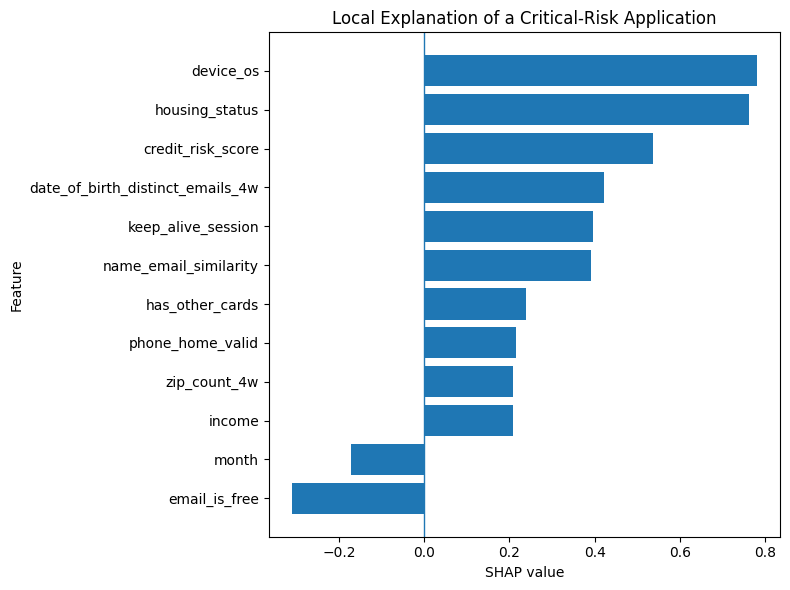

In [28]:
top_local = (
    example_explanation
    .head(12)
    .sort_values("shap_value")
)

plt.figure(figsize=(8, 6))

plt.barh(
    top_local["feature"],
    top_local["shap_value"]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel("SHAP value")
plt.ylabel("Feature")
plt.title(
    "Local Explanation of a Critical-Risk Application"
)

plt.tight_layout()
plt.show()

In [29]:
low_indices = test_risk[
    test_risk["risk_band"] == "Low"
].index

low_example_idx = low_indices[0]

low_example_application = (
    X_test_cb.iloc[[low_example_idx]]
)

print(
    "Actual fraud label:",
    y_test.iloc[low_example_idx]
)

print(
    "Calibrated fraud probability:",
    test_calibrated_proba[
        low_example_idx
    ]
)

Actual fraud label: 0
Calibrated fraud probability: 0.0017592034012743896


In [30]:
low_example_pool = Pool(
    low_example_application,
    cat_features=cat_features
)

low_shap_full = (
    final_cat_model
    .get_feature_importance(
        low_example_pool,
        type="ShapValues"
    )
)

low_shap = low_shap_full[
    0, :-1
]

low_explanation = pd.DataFrame({
    "feature":
        low_example_application.columns,

    "value":
        low_example_application
        .iloc[0]
        .values,

    "shap_value":
        low_shap
})

low_explanation["abs_shap"] = (
    np.abs(
        low_explanation[
            "shap_value"
        ]
    )
)

low_explanation = (
    low_explanation
    .sort_values(
        "abs_shap",
        ascending=False
    )
)

display(
    low_explanation.head(15)
)

,feature,value,shap_value,abs_shap
21,has_other_cards,1,-0.884853,0.884853
17,housing_status,BA,0.807225,0.807225
0,income,0.9,0.489189,0.489189
27,keep_alive_session,1,-0.350752,0.350752
18,phone_home_valid,1,-0.346663,0.346663
26,device_os,other,-0.337463,0.337463
16,email_is_free,0,-0.322120,0.322120
12,bank_branch_count_8w,0,0.313951,0.313951
36,valid_phone_count,2,-0.285476,0.285476
29,month,7,-0.220579,0.220579


### Example Low-Risk Explanation

The selected Low-risk application received a calibrated fraud probability of approximately 0.18% and was correctly classified as non-fraud.

Several features reduced the model's fraud-risk score. The strongest downward contributions came from having other cards, maintaining the session, valid phone information, the device operating-system category, a non-free email indicator, greater name-email similarity, and longer current-address history.

Some characteristics still increased the predicted risk, including housing status, income, bank-branch activity, missing-information count, and credit-risk score. However, their combined influence was outweighed by the stronger negative SHAP contributions.

This illustrates that the model evaluates applications using multiple interacting signals rather than relying on a single rule.

## 5. Critical vs Low-Risk Comparison

The local explanations show clear differences in the feature patterns associated with high- and low-risk predictions.

The Critical-risk case was pushed upward by several identity, device, contact, and behavioral signals, including low name-email similarity, invalid home-phone information, lack of other cards, and session characteristics.

In contrast, the Low-risk case received strong downward contributions from valid contact information, having other cards, session persistence, greater name-email similarity, and longer address history.

These examples demonstrate how the same model can combine multiple features differently across applications. The SHAP explanations describe model behavior and should not be interpreted as causal evidence of fraud.